In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [13]:
df = pd.read_csv("HR_comma_sep (1).csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 14999
Columns: 10


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [14]:
print(df.isnull().sum())

df["employment_status"] = df["left"].map({
    0: "Stayed",
    1: "Left"
})

df[["left", "employment_status"]].head()

counts = df["employment_status"].value_counts()

percentages = df["employment_status"].value_counts(
    normalize=True
) * 100

summary = pd.DataFrame({
    "Count": counts,
    "Percentage": percentages
})

print(summary)



satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64
                   Count  Percentage
employment_status                   
Stayed             11428   76.191746
Left                3571   23.808254


The overall employee attrition rate was 23.8%, calculated by dividing the number of employees who left by the total number of employees in the dataset.

In [15]:
hours_summary = df.groupby("employment_status")[
    "average_montly_hours"
].agg(["count", "mean", "median", "std"])

print(hours_summary)

                   count        mean  median        std
employment_status                                      
Left                3571  207.419210   224.0  61.202825
Stayed             11428  199.060203   198.0  45.682731


I chose average monthly working hours because I wanted to investigate whether employees who work longer hours are more likely to leave the company. Employees who left had a median of 224 working hours per month, compared with 198 hours for employees who stayed, a difference of 26 hours. The Left group also had a higher standard deviation of 61.20 hours compared with 45.68 hours for the Stayed group. This difference is reflected in the boxplots, where employees who left have a greater spread in their working hours. Although the distributions overlap, employees who left generally worked longer hours and showed greater variability.

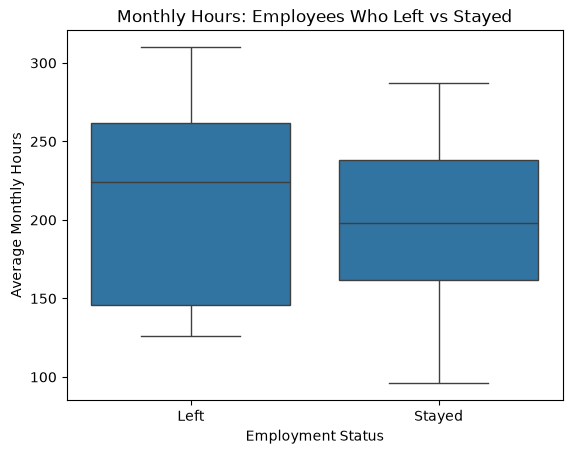

In [16]:
sns.boxplot(
    data=df,
    x="employment_status",
    y="average_montly_hours",
    order=["Left", "Stayed"]
)

plt.title("Monthly Hours: Employees Who Left vs Stayed")
plt.xlabel("Employment Status")
plt.ylabel("Average Monthly Hours")

plt.show()

Employees who left had a higher median number of monthly working hours compared with employees who stayed. The Left group also displayed greater variability, as indicated by the larger spread in its boxplot.

In [17]:
left_group = df[
    df["employment_status"] == "Left"
]["average_montly_hours"].dropna()

stayed_group = df[
    df["employment_status"] == "Stayed"
]["average_montly_hours"].dropna()

In [18]:
t_stat, p_value = stats.ttest_ind(
    left_group,
    stayed_group,
    equal_var=False
)

mean_difference = left_group.mean() - stayed_group.mean()

print("Mean Difference:", mean_difference)
print("T Statistic:", t_stat)
print("P-value:", f"{p_value:.3e}")

Mean Difference: 8.359007295086116
T Statistic: 7.5322885070798735
P-value: 5.907e-14


In [19]:
r, p = stats.pearsonr(
    df["average_montly_hours"],
    df["last_evaluation"]
)

print("Pearson correlation:", r)
print("P-value:", f"{p:.3e}")

Pearson correlation: 0.33974179983835895
P-value: 0.000e+00


Null Hypothesis (H₀): There is no difference in the average monthly working hours between employees who left and employees who stayed.

Alternative Hypothesis (H₁): There is a difference in the average monthly working hours between employees who left and employees who stayed.

A two-sided Welch independent-samples t-test was conducted to determine whether the difference in average monthly working hours between the two groups was statistically significant. Employees who left worked an average of 207.42 hours per month, compared with 199.06 hours for employees who stayed, resulting in a mean difference (Left minus Stayed) of 8.36 hours. The test produced a t-statistic of 7.5323 and a p-value of 5.907 × 10⁻¹⁴.

Because the p-value is below the significance level of 0.05, the null hypothesis is rejected. This indicates a statistically significant difference in average monthly working hours between employees who left and those who stayed.

For the HR director, these results suggest that employees who leave tend to work approximately 8.36 more hours per month than employees who remain with the company. Although this difference is statistically significant, it does not necessarily mean that working longer hours causes employees to leave.

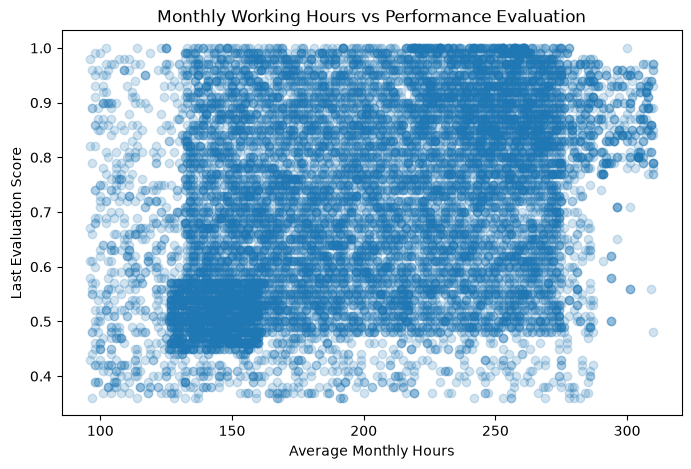

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["average_montly_hours"],
    df["last_evaluation"],
    alpha=0.2
)

plt.title("Monthly Working Hours vs Performance Evaluation")
plt.xlabel("Average Monthly Hours")
plt.ylabel("Last Evaluation Score")

plt.show()

The Pearson correlation between average monthly working hours and employee evaluation scores was r = 0.3397, with a p-value reported as 0.000e+00 due to numerical precision. This indicates a moderate positive linear relationship between working hours and employee evaluations. The scatterplot supports this finding, as employees who work more hours generally tend to receive higher evaluation scores. However, the points are widely distributed, suggesting that working hours alone do not explain much of the variation in evaluation scores.

The relationship is statistically significant at the 0.05 level, meaning there is strong evidence of a positive association between working hours and evaluations. However, the moderate correlation indicates that working hours are not a reliable predictor of an individual employee's evaluation score. Other factors, such as employee experience, job responsibilities, and individual performance, may also influence evaluations. Additionally, this correlation does not establish that working longer hours causes employees to receive higher evaluations.

The analysis found that employees who left the company worked an average of 207.42 hours per month, compared with 199.06 hours for employees who stayed, a statistically significant difference of 8.36 hours. Additionally, the Pearson correlation between monthly working hours and employee evaluation scores was r = 0.3397, indicating a moderate positive relationship where employees working longer hours generally received higher evaluations. These findings suggest that working hours may be associated with both employee retention and performance, although the data does not establish causation. HR should investigate whether employees who consistently work longer hours experience higher levels of stress or job dissatisfaction that may contribute to employee attrition.